# Ocular dominance - group analysis (v6)

**Simplified version** (decided with the supervisor): one weight, one filter, one strength measure.

| | v6 | v5 |
|---|---|---|
| Vertex weight (everywhere) | **mean pRF R² of the two eyes** | GLM R², min of the two eyes |
| Vertex filter | prf_analysis filters on both eyes **+ β > 0 for both eyes** | prf_analysis filters on both eyes |
| Strength measure | **OD index** `(β̄_FE − β̄_AE) / (β̄_FE + β̄_AE)` | response advantage (%) |
| Map reproducibility | **OD index of each vertex**, weighted Pearson r + weighted Deming regression | β_FE − β_AE, weighted rank correlation |

**Story**

1. **How much cortex prefers each eye?** Weighted % of vertices preferring FE-LE (Figure 1). Amblyopes: FE > AE expected; controls: no left / right difference expected.
2. **How strong is the dominance?** ROI OD index (Figure 2).
3. **Is it reproducible, and does it come from the eye?** OD maps of two independent halves of the runs, true eyes vs crossed labels (Figure 3).
4. Supplementary: biases (eye order, vertex selection), subject-level replication, between-group comparison, diagnostics.

**Why the β > 0 filter.** The OD index of a vertex only makes sense when both eyes respond positively to the common regressor. β ≤ 0 means that the eye does not respond, or not in the way the regressor assumes: noise on a weak response (mostly the amblyopic eye), or pRFs at different positions for the two eyes (the common regressor then does not describe one of the eyes). These vertices cannot be used to compare two responses. The filter is symmetric for both eyes and set a priori; it tends to remove vertices where the amblyopic eye is the weakest, so it is **conservative** (it can only reduce the fellow-eye dominance). The number of removed vertices is reported per group and ROI.

**Why the mean pRF R².** The weight comes from the pRF fits, an earlier and independent step: it does not depend on the betas used to measure the dominance. It is the usual weight of the pRF analyses (prf_analysis figures).

**Conventions:** FE-LE = fellow eye (amblyopes) / left eye (controls); AE-RE = amblyopic eye / right eye. Bars = median across subjects, error bars = 25th-75th percentiles. Stars = test within each group (amblyopes one-sided in the direction of the hypothesis, controls two-sided unless stated), FDR over the 8 ROIs: \* p < 0.05, \*\* < 0.01, \*\*\* < 0.001. Non-parametric tests (Wilcoxon) because of small groups (12, 8), bounded measures and a few atypical subjects. Nothing is written in the data folders; figures go to `Desktop/fig_od` (suffix `_v6`).

In [1]:
# Stop warnings
import warnings
warnings.filterwarnings("ignore")

# General imports
import os
import sys
import numpy as np
import pandas as pd
from scipy import stats, integrate
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Personal imports
sys.path.append("{}/../../analysis_code/utils".format(os.getcwd()))
from settings_utils import load_settings
from pycortex_utils import set_pycortex_config_file, get_rois, load_surface_pycortex
from plot_utils import plotly_template

In [2]:
# Directories
main_dir = '/Users/uriel/disks/meso_shared'
project_dir = 'amblyo7T_prf'
pp_dir = '{}/{}/derivatives/pp_data'.format(main_dir, project_dir)
fig_dir = '/Users/uriel/Desktop/fig_od'
cache_dir = '/Users/uriel/Desktop/fig_od/od_glm_common_cache'       # per-run GLM sums (od_glm_common_analysis.ipynb)
os.makedirs(fig_dir, exist_ok=True)

# Settings
base_dir = os.path.abspath(os.path.join(os.getcwd(), "../../"))
settings = load_settings([os.path.join(base_dir, project_dir, f) for f in
                          ["settings.yml", "prf-analysis.yml", "figure-settings.yml"]])
analysis_info = settings[0]
patients = analysis_info['group-patient']
controls = analysis_info['group-control']
subjects = analysis_info['subjects']
maps_names_css = analysis_info['maps_names_css']
maps_names_css_stats = analysis_info['maps_names_css_stats']
maps_names_css_od = analysis_info['maps_names_css_od']

# Analysis
task = 'BarsBarsRingsWedges'
file_spec = '{}/{}/fsnative/prfmodel/prf_derivatives/{}_task-{}{}_hemi-{}_fmriprep_dct_psc_concat_prf-css_{}.func.gii'
rois_to_keep = ['V1', 'V2', 'V3', 'V4', 'V3A', 'V3B', 'LO1', 'LO2']
eyes = {'L': 'LeftEye', 'R': 'RightEye'}

# prf_analysis filters (applied to both eyes)
ecc_th = analysis_info['ecc_th']
size_th = analysis_info['size_th']
n_th = analysis_info['n_th']
rsqr_th = analysis_info['rsqr_th']
amp_th = analysis_info['prf_amp_th']
amp_th = amp_th['psc'] if isinstance(amp_th, dict) else amp_th
stats_th = analysis_info['stats_th']
p_name = 'corr_pvalue_5pt' if stats_th == 0.05 else 'corr_pvalue_1pt'

# Amblyopic eye of each patient
participants = pd.read_csv('{}/{}/participants.tsv'.format(main_dir, project_dir), sep='\t')
ambly_eye = {s: str(e).split(' ')[0] for s, e in zip(participants.participant_id, participants.amblyopic_eye)
             if str(e).split(' ')[0] in ('L', 'R')}

# Eye scanned first (read only: sourcedata/participant-mapping.md + participant_mapping.tsv)
src_dir = '{}/{}/sourcedata'.format(main_dir, project_dir)
mapping = pd.read_csv('{}/participant_mapping.tsv'.format(src_dir), sep='\t', dtype=str).dropna(subset=['initials'])
initials_to_sub = {i.strip(): b.strip() for i, b in zip(mapping.initials, mapping.bids_name)}
first_eye = {}
with open('{}/participant-mapping.md'.format(src_dir)) as f:
    for line in f:
        if 'eye first' in line:
            initials, txt = line.split(',', 1)
            first_eye[initials_to_sub[initials.strip()]] = 'L' if 'LEFT' in txt.upper() else 'R'

# Pycortex database (ROIs)
cortex_dir = '{}/{}/derivatives/pp_data/cortex'.format(main_dir, project_dir)
set_pycortex_config_file(cortex_dir)

In [3]:
def bh_fdr(p):
    """Benjamini-Hochberg FDR correction."""
    p = np.asarray(p, float)
    o = np.argsort(p)
    q = p[o] * len(p) / (np.arange(len(p)) + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    out = np.empty_like(q)
    out[o] = np.minimum(q, 1)
    return out


def wcorr(x, y, w):
    """Weighted rank correlation: Pearson correlation of the ranks of x and y, each vertex weighted by w."""
    x, y, w = stats.rankdata(x), stats.rankdata(y), np.asarray(w, float)
    if np.sum(w) == 0:
        return np.nan
    mx, my = np.sum(w * x) / np.sum(w), np.sum(w * y) / np.sum(w)
    return np.sum(w * (x - mx) * (y - my)) / np.sqrt(np.sum(w * (x - mx) ** 2) * np.sum(w * (y - my) ** 2))


def stars(p):
    return '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else ''


def bf10_ttest(x, h0=0, r=np.sqrt(2) / 2):
    """JZS Bayes factor BF10 of a one-sample t-test (Rouder et al. 2009), Cauchy prior of scale r on the effect size."""
    x = np.asarray(x, float)
    x = x[np.isfinite(x)] - h0
    n, v = x.size, x.size - 1
    t = x.mean() / (x.std(ddof=1) / np.sqrt(n))
    null = (1 + t ** 2 / v) ** (-(v + 1) / 2)
    alt = integrate.quad(lambda g: (1 + n * g * r ** 2) ** -0.5
                         * (1 + t ** 2 / ((1 + n * g * r ** 2) * v)) ** (-(v + 1) / 2)
                         * (2 * np.pi) ** -0.5 * g ** -1.5 * np.exp(-1 / (2 * g)), 0, np.inf)[0]
    return alt / null


def within_tests(df, value, h0, alt_patient='greater', alt_control='two-sided'):
    """Per ROI: Wilcoxon of each group vs h0 (FDR over the ROIs) + Bayes factor BF01 of the controls."""
    rows = []
    for roi in rois_to_keep:
        d = df[df.roi == roi]
        vp, vc = d[d.group == 'patient'][value].dropna(), d[d.group == 'control'][value].dropna()
        rows.append({'roi': roi, 'median_patients': vp.median(), 'median_controls': vc.median(),
                     'p_patients': stats.wilcoxon(vp - h0, alternative=alt_patient).pvalue,
                     'p_controls': stats.wilcoxon(vc - h0, alternative=alt_control).pvalue,
                     'BF01_controls': 1 / bf10_ttest(vc, h0)})
    s = pd.DataFrame(rows).set_index('roi')
    s['p_patients_fdr'] = bh_fdr(s.p_patients)
    s['p_controls_fdr'] = bh_fdr(s.p_controls)
    return s


# Figure settings (as the other pRF figures)
template_specs = dict(axes_color="rgba(0, 0, 0, 1)", axes_width=2, axes_font_size=15,
                      bg_col="rgba(255, 255, 255, 1)", font='Arial', title_font_size=15, rois_plot_width=1.5)
fig_template = plotly_template(template_specs)
roi_colors_rgb = analysis_info['roi_colors']
fig_margin = analysis_info['rois_fig_margin']
bar_width = analysis_info['rois_bar_width']
rois_plot_height = analysis_info['rois_plot_height']
rois_hor_spacing = 50
ctrl_color = 'rgb(150,150,150)'
groups = ['patient', 'control']
group_labels = {'patient': 'Amblyopes', 'control': 'Controls'}
cols = len(rois_to_keep)
fig_height = rois_plot_height * 2 + fig_margin[1] + fig_margin[3]
fig_width = bar_width * 4 * cols + fig_margin[0] + fig_margin[2] + (rois_hor_spacing * (cols - 1))
hor_spacing = rois_hor_spacing / (fig_width - fig_margin[0] - fig_margin[2])


def bar_figure(df, values, s, y_title, y_ticks, tick_fmt, fn_out, legends=None, patterns=None):
    """Median and 25-75 percentiles per group and ROI; stars = within-group test of s (FDR)."""
    patterns = patterns or [''] * len(values)
    y_step = (y_ticks[-1] - y_ticks[0]) * 0.05
    fig = make_subplots(rows=1, cols=cols, subplot_titles=rois_to_keep, horizontal_spacing=hor_spacing)
    for col_idx, roi in enumerate(rois_to_keep, start=1):
        d = df[df.roi == roi]
        top = {group: -np.inf for group in groups}
        for value, pattern in zip(values, patterns):
            med, p25, p75 = [], [], []
            for group in groups:
                v = d[d.group == group][value].dropna()
                med.append(v.median()); p25.append(np.nanpercentile(v, 25)); p75.append(np.nanpercentile(v, 75))
                top[group] = max(top[group], np.nanpercentile(v, 75), v.median(), 0)
            med, p25, p75 = np.array(med), np.array(p25), np.array(p75)
            fig.add_trace(go.Bar(x=[group_labels[g] for g in groups], y=med, offsetgroup=value,
                                 marker=dict(color=[roi_colors_rgb[roi], ctrl_color],
                                             pattern=dict(shape=pattern, fgcolor='rgba(0,0,0,1)',
                                                          bgcolor='rgba(0,0,0,0)', size=8)),
                                 error_y=dict(type='data', array=p75 - med, arrayminus=med - p25, visible=True,
                                              thickness=2, width=0, color='rgba(0,0,0,1)'),
                                 showlegend=False),
                          row=1, col=col_idx)
        xref, yref = 'x{}'.format('' if col_idx == 1 else col_idx), 'y{}'.format('' if col_idx == 1 else col_idx)
        for x_pos, group in enumerate(groups):
            p = s.loc[roi, 'p_{}_fdr'.format('patients' if group == 'patient' else 'controls')]
            fig.add_annotation(x=x_pos, y=top[group] + y_step / 2, xref=xref, yref=yref, text=stars(p),
                               showarrow=False, font=dict(size=16, color='black'), yanchor='bottom')
        fig.add_shape(type='line', x0=0, x1=0, y0=y_ticks[0], y1=y_ticks[-1], xref='{} domain'.format(xref), yref=yref,
                      line=dict(color=template_specs['axes_color'], width=template_specs['axes_width']))
    if legends:
        for legend, pattern in zip(legends, patterns):
            fig.add_trace(go.Bar(x=[None], y=[None], name=legend,
                                 marker=dict(color='rgba(128,128,128,1)',
                                             pattern=dict(shape=pattern, fgcolor='rgba(0,0,0,1)',
                                                          bgcolor='rgba(0,0,0,0.3)', size=8)),
                                 showlegend=True), row=1, col=1)
    fig.update_xaxes(showline=True, ticklen=0, linecolor='rgba(255,255,255,0)', tickangle=0)
    fig.update_yaxes(showline=False, range=[y_ticks[0], y_ticks[-1] + 3 * y_step], tickvals=y_ticks,
                     ticktext=[tick_fmt.format(t) for t in y_ticks], showticklabels=True)
    fig.update_yaxes(title_text=y_title, row=1, col=1)
    fig.update_layout(barmode='group', bargap=0.3, bargroupgap=0.05, height=fig_height, width=fig_width,
                      template=fig_template,
                      legend=dict(orientation='h', font_family=template_specs['font'],
                                  font_size=template_specs['axes_font_size'], x=1, y=1.15, xanchor='right',
                                  yanchor='bottom', bgcolor='rgba(0,0,0,0)', traceorder='normal', itemwidth=30),
                      margin_l=fig_margin[0], margin_t=fig_margin[1] + 40, margin_r=fig_margin[2], margin_b=fig_margin[3])
    fig.show()
    fig.write_image('{}/{}.pdf'.format(fig_dir, fn_out))


def nice_ticks(values, step):
    lo = min(0, np.floor(np.nanmin(values) / step) * step)
    hi = max(step, np.ceil(np.nanmax(values) / step) * step)
    return np.round(np.arange(lo, hi + step / 2, step), 3)


def wpearson(x, y, w):
    """Weighted Pearson correlation (= correlation of a weighted linear regression)."""
    x, y, w = np.asarray(x, float), np.asarray(y, float), np.asarray(w, float)
    if np.sum(w) == 0 or len(x) < 3:
        return np.nan
    mx, my = np.sum(w * x) / np.sum(w), np.sum(w * y) / np.sum(w)
    return np.sum(w * (x - mx) * (y - my)) / np.sqrt(np.sum(w * (x - mx) ** 2) * np.sum(w * (y - my) ** 2))


def deming(x, y, w=None):
    """Weighted Deming (orthogonal) regression, as in make_corr_tsv.py: returns slope, intercept.
    Symmetric in x and y (both halves are measured with noise), weights normalised to sum 1."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    w = np.ones_like(x) if w is None else np.asarray(w, float)
    ok = np.isfinite(x) & np.isfinite(y) & np.isfinite(w)
    x, y, w = x[ok], y[ok], w[ok]
    if len(x) < 3 or np.sum(w) == 0:
        return np.nan, np.nan
    w = w / np.sum(w)
    mx, my = np.sum(w * x), np.sum(w * y)
    sxx, syy, sxy = np.sum(w * (x - mx) ** 2), np.sum(w * (y - my) ** 2), np.sum(w * (x - mx) * (y - my))
    if sxy == 0:
        return np.nan, np.nan
    slope = (syy - sxx + np.sqrt((syy - sxx) ** 2 + 4 * sxy ** 2)) / (2 * sxy)
    return slope, my - slope * mx


def od_index(b_fe, b_ae):
    """OD index (FE - AE) / (FE + AE); defined for positive betas only."""
    with np.errstate(divide='ignore', invalid='ignore'):
        return np.where((b_fe > 0) & (b_ae > 0), (b_fe - b_ae) / (b_fe + b_ae), np.nan)

## Load the data: measures per subject and ROI

Per subject and ROI (vertices kept: prf_analysis filters on both eyes **and** β > 0 for both eyes; weight w = mean pRF R² of both eyes):

- `pref_FE-LE` / `pref_AE-RE`: weighted % of vertices preferring each eye, `100 · Σ w·[β_FE > β_AE] / Σ w` (Figure 1);
- `od_index`: ROI OD index `(β̄_FE − β̄_AE) / (β̄_FE + β̄_AE)`, β̄ = weighted mean β of the ROI (Figure 2). The betas are averaged **before** the ratio: a vertex with a tiny or noisy preference adds almost the same amount to both eyes and barely moves the index;
- β > 0 filter bookkeeping: % of the vertices (and of the weight) passing the pRF filters that are removed, and which eye had β ≤ 0;
- `pref_fe_sel` / `pref_ae_sel`, `rsq_fe` / `rsq_ae`: vertex-selection checks (supplementary).

In [4]:
def select(d, st):
    """prf_analysis filters of one eye + positive pRF amplitude."""
    return ((d['prf_ecc'] >= ecc_th[0]) & (d['prf_ecc'] <= ecc_th[1])
            & (d['prf_size'] >= size_th[0]) & (d['prf_size'] <= size_th[1])
            & (d['prf_n'] >= n_th[0]) & (d['prf_n'] <= n_th[1])
            & (d['prf_rsq'] >= rsqr_th)
            & (d['amplitude'] >= amp_th[0]) & (d['amplitude'] <= amp_th[1]) & (d['amplitude'] > 0)
            & (st[maps_names_css_stats.index(p_name)] <= stats_th))


def pref_percent(b_a, b_b, w):
    return 100 * np.sum(w * (b_a > b_b)) / np.sum(w) if np.sum(w) > 0 else np.nan


def roi_od(b_fe, b_ae, w):
    if np.sum(w) == 0:
        return np.nan
    m_fe, m_ae = np.sum(w * b_fe) / np.sum(w), np.sum(w * b_ae) / np.sum(w)
    return (m_fe - m_ae) / (m_fe + m_ae) if (m_fe > 0) & (m_ae > 0) else np.nan


rows, vertex_data = [], {}
for subject in subjects:
    group = 'patient' if subject in patients else 'control'

    # Betas of each eye (OD image of make_od_img.py)
    fns = [file_spec.format(pp_dir, subject, subject, task, '', hemi, 'od') for hemi in ['L', 'R']]
    if not all(os.path.isfile(fn) for fn in fns):
        print('{}: OD image missing, skipped'.format(subject))
        continue
    od_mat = load_surface_pycortex(L_fn=fns[0], R_fn=fns[1])['data_concat']
    beta = {'L': od_mat[maps_names_css_od.index('od_beta_le')], 'R': od_mat[maps_names_css_od.index('od_beta_re')]}

    # pRF derivatives and stats of each eye
    keep_eye, rsq_eye = {}, {}
    for e, eye in eyes.items():
        deriv = load_surface_pycortex(L_fn=file_spec.format(pp_dir, subject, subject, task, eye, 'L', 'deriv'),
                                      R_fn=file_spec.format(pp_dir, subject, subject, task, eye, 'R', 'deriv'))['data_concat']
        st = load_surface_pycortex(L_fn=file_spec.format(pp_dir, subject, subject, task, eye, 'L', 'stats'),
                                   R_fn=file_spec.format(pp_dir, subject, subject, task, eye, 'R', 'stats'))['data_concat']
        d = {name: deriv[i] for i, name in enumerate(maps_names_css)}
        keep_eye[e] = select(d, st) & np.isfinite(beta[e])
        rsq_eye[e] = d['prf_rsq']
    weight = np.nan_to_num(np.clip(np.nanmean([rsq_eye['L'], rsq_eye['R']], axis=0), 0, None))   # mean pRF R² of both eyes

    # FE-LE / AE-RE: amblyopes -> fellow / amblyopic eye, controls -> left / right eye
    fe, ae = ('R', 'L') if ambly_eye.get(subject) == 'L' else ('L', 'R')
    b_fe, b_ae = beta[fe], beta[ae]
    keep_prf = keep_eye['L'] & keep_eye['R']                        # pRF filters on both eyes
    pos = (b_fe > 0) & (b_ae > 0)                                   # β > 0 for both eyes
    keep = keep_prf & pos
    vertex_data[subject] = {'fe': fe, 'keep': keep, 'w': weight}

    rois = get_rois(subject=subject, surf_format='fsnative', rois_type='rois-mmp', mask=True, rois=None, hemis=None)
    for roi in rois_to_keep:
        m_prf = rois[roi] & keep_prf
        mask = m_prf & pos
        w = weight[mask]
        if mask.sum() < 10 or np.sum(w) == 0:
            continue
        mask_fe, mask_ae = rois[roi] & keep_eye[fe] & pos, rois[roi] & keep_eye[ae] & pos
        rows.append({'subject': subject, 'group': group, 'roi': roi, 'n_vertices': mask.sum(),
                     'fe_le_first': first_eye[subject] == fe,
                     # beta > 0 filter bookkeeping
                     'removed_pct': 100 * (1 - mask.sum() / m_prf.sum()),
                     'removed_w_pct': 100 * (1 - np.sum(weight[mask]) / np.sum(weight[m_prf])),
                     'removed_fe_neg_pct': 100 * np.sum(m_prf & (b_fe <= 0) & (b_ae > 0)) / m_prf.sum(),
                     'removed_ae_neg_pct': 100 * np.sum(m_prf & (b_ae <= 0) & (b_fe > 0)) / m_prf.sum(),
                     'removed_both_neg_pct': 100 * np.sum(m_prf & (b_fe <= 0) & (b_ae <= 0)) / m_prf.sum(),
                     # measures
                     'pref_FE-LE': pref_percent(b_fe[mask], b_ae[mask], w),
                     'pref_AE-RE': pref_percent(b_ae[mask], b_fe[mask], w),
                     'od_index': roi_od(b_fe[mask], b_ae[mask], w),
                     # vertex-selection checks
                     'pref_fe_sel': pref_percent(b_fe[mask_fe], b_ae[mask_fe], weight[mask_fe]),
                     'pref_ae_sel': pref_percent(b_fe[mask_ae], b_ae[mask_ae], weight[mask_ae]),
                     'rsq_fe': np.nanmedian(rsq_eye[fe][mask]), 'rsq_ae': np.nanmedian(rsq_eye[ae][mask])})
    print('{}: done'.format(subject))
df_subjects = pd.DataFrame(rows)
df_subjects.groupby(['group', 'roi'])[['n_vertices', 'pref_FE-LE', 'od_index']].median().unstack('group').reindex(rois_to_keep).round(3)

sub-01: done
sub-02: done
sub-03: done
sub-04: done
sub-05: done
sub-06: done
sub-07: done
sub-08: done
sub-09: done
sub-10: done
sub-11: done
sub-12: done
sub-13: done
sub-14: done
sub-16: done
sub-17: done
sub-18: done
sub-19: done
sub-20: done
sub-21: done


n_vertices         pref_FE-LE         od_index        
group    control patient    control patient  control patient
roi                                                         
V1        5096.0  4283.5     51.424  57.927    0.001   0.020
V2        4671.5  4105.0     56.209  62.640    0.018   0.091
V3        3196.5  2954.5     56.629  69.909    0.023   0.131
V4        2645.5  2452.5     57.802  71.463    0.028   0.111
V3A        782.0   997.0     53.217  70.902   -0.003   0.129
V3B        320.5   509.0     46.095  83.304   -0.014   0.109
LO1        485.5   428.5     56.755  78.435    0.002   0.141
LO2        455.5   291.5     72.801  71.402    0.093   0.112

### Vertices removed by the β > 0 filter

Median across subjects, % of the vertices passing the pRF filters: removed in total, removed in % of the weight, and which eye had β ≤ 0 (FE-LE only, AE-RE only, both). Amblyopes: if mostly the amblyopic eye has β ≤ 0, the filter removes vertices where the amblyopic eye is weakest, i.e. it can only reduce the fellow-eye dominance (conservative). The last column tests, in the amblyopes, whether β ≤ 0 is more frequent for the AE than for the FE (paired Wilcoxon, two-sided, FDR).

In [5]:
cols_rm = ['removed_pct', 'removed_w_pct', 'removed_fe_neg_pct', 'removed_ae_neg_pct', 'removed_both_neg_pct']
rm = df_subjects.groupby(['group', 'roi'])[cols_rm].median().round(1)
pat = df_subjects[df_subjects.group == 'patient']
p_rm = [stats.wilcoxon(pat[pat.roi == roi].removed_ae_neg_pct, pat[pat.roi == roi].removed_fe_neg_pct).pvalue for roi in rois_to_keep]
rm_p = pd.Series(bh_fdr(p_rm), index=rois_to_keep, name='p_fdr AE vs FE (amblyopes)').round(3)
print(rm.unstack('group').reindex(rois_to_keep).to_string())
print()
print(rm_p.to_string())

      removed_pct         removed_w_pct         removed_fe_neg_pct         removed_ae_neg_pct         removed_both_neg_pct        
group     control patient       control patient            control patient            control patient              control patient
roi                                                                                                                               
V1            0.3     0.4           0.0     0.0                0.2     0.2                0.1     0.2                  0.0     0.0
V2            0.3     0.5           0.0     0.1                0.2     0.2                0.1     0.2                  0.0     0.0
V3            0.1     0.3           0.0     0.0                0.1     0.2                0.0     0.1                  0.0     0.0
V4            0.0     0.1           0.0     0.0                0.0     0.0                0.0     0.0                  0.0     0.0
V3A           0.1     0.1           0.0     0.0                0.0     0.0         

## Figure 1 — how much cortex prefers each eye

**Measure:** weighted % of vertices preferring the FE-LE eye. 50 % = no preference.

**Amblyopes:** Wilcoxon vs 50 %, one-sided (FE > AE), FDR over the 8 ROIs. **Controls:** the hypothesis is the absence of dominance; a non-significant test does not show it, so we add the **Bayes factor BF01** (JZS t-test, Cauchy prior r = 0.707): BF01 > 3 = moderate evidence for no dominance, 1-3 = anecdotal, < 1 = favours a dominance. Two-sided Wilcoxon vs 50 %.

Each vertex votes for one eye, whatever the size of its preference: this says how much cortex prefers each eye, not how strongly (Figure 2).

In [6]:
s_pref = within_tests(df_subjects, 'pref_FE-LE', 50)
print('% of vertices preferring FE-LE (H0 = 50 %): amblyopes one-sided, controls two-sided')
s_pref[['median_patients', 'p_patients_fdr', 'median_controls', 'p_controls_fdr', 'BF01_controls']].round(3)

% of vertices preferring FE-LE (H0 = 50 %): amblyopes one-sided, controls two-sided


,median_patients,p_patients_fdr,median_controls,p_controls_fdr,BF01_controls
roi,,,,,
V1,57.927,0.013,51.424,0.615,1.868
V2,62.640,0.014,56.209,0.615,1.479
V3,69.909,0.013,56.629,0.615,2.099
V4,71.463,0.007,57.802,0.615,1.923
V3A,70.902,0.006,53.217,1.000,2.950
V3B,83.304,0.015,46.095,0.732,2.456
LO1,78.435,0.007,56.755,0.615,1.853
LO2,71.402,0.032,72.801,0.615,1.127


In [7]:
bar_figure(df_subjects, ['pref_FE-LE', 'pref_AE-RE'], s_pref, 'Preferring vertices (%)', np.linspace(0, 100, 5), '{:.0f}',
           'od_v6_fig1_pref_percent', legends=['FE / LE', 'AE / RE'], patterns=['', '/'])

## Figure 2 — how strong is the dominance

**Measure:** ROI OD index `(β̄_FE − β̄_AE) / (β̄_FE + β̄_AE)`, β̄ = weighted mean β of the ROI. 0 = both eyes respond equally; +0.1 = the fellow eye responds 1.22 times more than the amblyopic eye ((1 + OD) / (1 − OD)); bounded between −1 and 1 and symmetric for the two eyes.

**Test:** Wilcoxon vs 0 (amblyopes one-sided, controls two-sided + BF01), FDR over the ROIs.

In [8]:
s_od = within_tests(df_subjects, 'od_index', 0)
print('ROI OD index (H0 = 0): amblyopes one-sided, controls two-sided')
s_od[['median_patients', 'p_patients_fdr', 'median_controls', 'p_controls_fdr', 'BF01_controls']].round(3)

ROI OD index (H0 = 0): amblyopes one-sided, controls two-sided


,median_patients,p_patients_fdr,median_controls,p_controls_fdr,BF01_controls
roi,,,,,
V1,0.020,0.028,0.001,0.945,2.449
V2,0.091,0.009,0.018,0.945,1.962
V3,0.131,0.013,0.023,0.945,2.139
V4,0.111,0.012,0.028,0.945,1.819
V3A,0.129,0.009,-0.003,0.945,2.737
V3B,0.109,0.088,-0.014,0.945,2.864
LO1,0.141,0.009,0.002,0.945,2.592
LO2,0.112,0.030,0.093,0.625,0.577


In [9]:
bar_figure(df_subjects, ['od_index'], s_od, 'OD index (FE-LE − AE-RE)',
           nice_ticks(df_subjects.groupby(['group', 'roi']).od_index.quantile([0.25, 0.75]), 0.05), '{:.2f}',
           'od_v6_fig2_od_index')

## Figure 3 — reproducibility of the OD maps and negative control

**Idea (as Nasr et al. 2025 and de Hollander et al. 2021):** split the runs into two independent halves, compute the OD map in each half, and check that the second half finds the map of the first one. If the betas were random, the two maps would not be related.

**Split:** half A = Bars01 + Bars02, half B = Rings + Wedges (both eyes in each half). With 4 runs per eye there are 3 ways to make two pairs; this is the only one where the negative control is valid (the two runs of half A have the same stimulus, see below). It is also the most demanding split: the two halves use different stimuli.

**Map of a half:** OD index of each vertex, `(β_FE − β_AE) / (β_FE + β_AE)`, with the betas of the 2 runs of the half (per-run sums of `od_glm_common_analysis.ipynb`). Vertices kept: the selection above, **and β > 0 for both eyes in both halves** (also for the crossed labels below, so that the true and crossed correlations use exactly the same vertices).

**Reproducibility:** for each subject and ROI, a **weighted linear regression** of the map of half B on the map of half A, weighted by the mean pRF R² (as the inter-eye parameter correlations of `make_corr_tsv.py`): weighted Pearson r (the statistic tested) and weighted **Deming** slope (orthogonal regression, symmetric because both halves contain noise; shown on the example scatter plots). r > 0 = a vertex that prefers the fellow eye in one half also prefers it in the other.

**Negative control: crossed labels.** In each half, pseudo-eye 1 = first run of the FE eye + second run of the AE eye, pseudo-eye 2 = the reverse. Stimuli, regressor, vertices and amount of data are identical, but the real eye difference cancels. If the reproducible maps come from the eye, the crossed r is ~0; if they came from the stimulus, the pRF model or run artefacts, it would be as high as the true r. In half A the two runs are both bars, so the crossed difference contains only run-to-run noise: this is why this split is required.

**Tests:** true r > 0 and true r > crossed r (Wilcoxon, one-sided, FDR over the ROIs, per group).

**Limit:** both halves contain runs of each eye scanned in the same order: a systematic order effect would also replicate. The order is tested in the supplementary biases. **Not done:** blind-spot control (stimulus ±10°, blind spot ~15°).

In [10]:
runs_A, runs_B = [0, 1], [2, 3]                       # A = Bars01 + Bars02, B = Rings + Wedges
sh_rows, sh_vertex = [], {}
for subject in df_subjects.subject.unique():
    cache_fn = '{}/{}_od-glm-common_runs.npz'.format(cache_dir, subject)
    if not os.path.isfile(cache_fn):
        print('{}: no per-run cache, skipped'.format(subject))
        continue
    cache = np.load(cache_fn)
    vd = vertex_data[subject]
    vert = cache['vertex']
    keep, w_all, roi_names = vd['keep'][vert], vd['w'][vert], cache['roi']
    fe_i, ae_i = (1, 0) if vd['fe'] == 'R' else (0, 1)            # cache eye order: 0 = left, 1 = right
    sxy, sxx = cache['sxy_common'], cache['sxx_common']

    def beta(items):
        """β of a group of (eye, run) items (same regressor for both eyes in a run)."""
        with np.errstate(divide='ignore', invalid='ignore'):
            return sum(sxy[e, r] for e, r in items) / sum(sxx[r] for _, r in items)

    b, b_cross = {}, {}
    for half, (r1, r2) in zip(['A', 'B'], [runs_A, runs_B]):
        b[half] = (beta([(fe_i, r1), (fe_i, r2)]), beta([(ae_i, r1), (ae_i, r2)]))
        b_cross[half] = (beta([(fe_i, r1), (ae_i, r2)]), beta([(ae_i, r1), (fe_i, r2)]))
    pos = np.all([(x > 0) for h in 'AB' for x in b[h] + b_cross[h]], axis=0)     # β > 0: both eyes, both halves, true and crossed
    od = {h: od_index(*b[h]) for h in 'AB'}
    od_cross = {h: od_index(*b_cross[h]) for h in 'AB'}
    sh_vertex[subject] = {'od_A': od['A'], 'od_B': od['B'], 'keep': keep & pos, 'roi': roi_names, 'w': w_all}

    for roi in rois_to_keep:
        m_sel = keep & (roi_names == roi)
        m = m_sel & pos
        w = w_all[m]
        if m.sum() < 10 or np.sum(w) == 0:
            continue
        slope, intercept = deming(od['A'][m], od['B'][m], w)
        sh_rows.append({'subject': subject, 'group': 'patient' if subject in patients else 'control', 'roi': roi,
                        'n_vertices': m.sum(), 'removed_halves_pct': 100 * (1 - m.sum() / m_sel.sum()),
                        'r_true': wpearson(od['A'][m], od['B'][m], w),
                        'r_crossed': wpearson(od_cross['A'][m], od_cross['B'][m], w),
                        'deming_slope': slope, 'deming_intercept': intercept,
                        'od_A': roi_od(b['A'][0][m], b['A'][1][m], w), 'od_B': roi_od(b['B'][0][m], b['B'][1][m], w)})
df_sh = pd.DataFrame(sh_rows)
print('Vertices removed by the β > 0 filter in the halves (median %, of the vertices kept above):')
print(df_sh.groupby(['group', 'roi']).removed_halves_pct.median().unstack('group').reindex(rois_to_keep).round(1).to_string())

# Tests per ROI and group: true r > 0, true r > crossed r (one-sided), crossed r vs 0 (two-sided); FDR over the ROIs
rows = []
for roi in rois_to_keep:
    for group in groups:
        dg = df_sh[(df_sh.roi == roi) & (df_sh.group == group)].dropna(subset=['r_true', 'r_crossed'])
        rows.append({'roi': roi, 'group': group, 'n': len(dg), 'r_true': dg.r_true.median(), 'r_crossed': dg.r_crossed.median(),
                     'deming_slope': dg.deming_slope.median(),
                     'p_true_vs_0': stats.wilcoxon(dg.r_true, alternative='greater').pvalue,
                     'p_true_vs_crossed': stats.wilcoxon(dg.r_true, dg.r_crossed, alternative='greater').pvalue,
                     'p_crossed_vs_0': stats.wilcoxon(dg.r_crossed).pvalue})
sh_stats = pd.DataFrame(rows)
for col in ['p_true_vs_0', 'p_true_vs_crossed', 'p_crossed_vs_0']:
    sh_stats[col + '_fdr'] = sh_stats.groupby('group')[col].transform(bh_fdr)
sh_stats = sh_stats.set_index(['group', 'roi'])
print('\nMap reproducibility (medians across subjects)')
print(sh_stats[['n', 'r_true', 'r_crossed', 'deming_slope', 'p_true_vs_0_fdr', 'p_true_vs_crossed_fdr', 'p_crossed_vs_0_fdr']].round(3).to_string())

Vertices removed by the β > 0 filter in the halves (median %, of the vertices kept above):
group  control  patient
roi                    
V1        16.9     23.5
V2        15.4     25.9
V3        10.2     11.9
V4         2.5      7.3
V3A        7.0     11.6
V3B       11.8      8.4
LO1        3.7     10.7
LO2        4.5     13.6

Map reproducibility (medians across subjects)
              n  r_true  r_crossed  deming_slope  p_true_vs_0_fdr  p_true_vs_crossed_fdr  p_crossed_vs_0_fdr
group   roi                                                                                                 
patient V1   12   0.289     -0.005         0.829            0.016                  0.021               0.904
control V1    8   0.187      0.001         0.164            0.023                  0.312               0.945
patient V2   12   0.483     -0.020         0.715            0.016                  0.014               0.904
control V2    8   0.193     -0.050         0.170            0.021            

### Figure 3A — example subjects

OD index of each vertex in half A (bars, x) and half B (rings + wedges, y), V1-V3, for a representative amblyope and a representative control (the subject of each group whose mean V1-V3 r is the closest to the group median: not the best subjects). Dot size ∝ weight; dashed = identity; solid = weighted Deming regression line.

In [11]:
early = ['V1', 'V2', 'V3']
mean_r = df_sh[df_sh.roi.isin(early)].groupby(['group', 'subject']).r_true.mean()
examples = {g: (mean_r[g] - mean_r[g].median()).abs().idxmin() for g in groups}
print('Representative subjects:', examples)

lim = 1
fig = make_subplots(rows=2, cols=3, horizontal_spacing=0.08, vertical_spacing=0.2,
                    subplot_titles=['{} {} - {}'.format(group_labels[g][:-1], examples[g], roi) for g in groups for roi in early])
for r_i, group in enumerate(groups, start=1):
    sv = sh_vertex[examples[group]]
    for c_i, roi in enumerate(early, start=1):
        m = sv['keep'] & (sv['roi'] == roi)
        x_v, y_v, w_v = sv['od_A'][m], sv['od_B'][m], sv['w'][m]
        slope, intercept = deming(x_v, y_v, w_v)
        n = (r_i - 1) * 3 + c_i
        xref, yref = 'x{}'.format('' if n == 1 else n), 'y{}'.format('' if n == 1 else n)
        color = roi_colors_rgb[roi] if group == 'patient' else ctrl_color
        fig.add_shape(type='line', x0=-lim, x1=lim, y0=-lim, y1=lim, xref=xref, yref=yref, line=dict(color='grey', dash='dash'))
        fig.add_trace(go.Scattergl(x=x_v, y=y_v, mode='markers', showlegend=False,
                                   marker=dict(size=2 + 8 * w_v / np.max(w_v), opacity=0.35, color=color)), row=r_i, col=c_i)
        fig.add_trace(go.Scatter(x=[-lim, lim], y=[intercept - slope * lim, intercept + slope * lim], mode='lines',
                                 line=dict(color='black', width=2), showlegend=False), row=r_i, col=c_i)
        fig.add_annotation(x=0.04, y=0.97, xref='{} domain'.format(xref), yref='{} domain'.format(yref), xanchor='left',
                           yanchor='top', showarrow=False, font=dict(size=14),
                           text='r = {:.2f}<br>slope = {:.2f}'.format(wpearson(x_v, y_v, w_v), slope))
fig.update_xaxes(range=[-lim, lim], title_text='OD index, bars', showline=True, zeroline=True, zerolinecolor='lightgrey')
fig.update_yaxes(range=[-lim, lim], title_text='OD index, rings + wedges', showline=True, zeroline=True, zerolinecolor='lightgrey')
fig.update_layout(template=fig_template, height=2 * rois_plot_height * 1.4 + fig_margin[1] + fig_margin[3],
                  width=3 * rois_plot_height * 1.4 + fig_margin[0] + fig_margin[2],
                  margin_l=fig_margin[0], margin_t=fig_margin[1] + 20, margin_r=fig_margin[2], margin_b=fig_margin[3])
fig.show()
fig.write_image('{}/od_v6_fig3A_split_half_maps.pdf'.format(fig_dir))

Representative subjects: {'patient': 'sub-09', 'control': 'sub-20'}


### Figure 3B — map correlation, true eyes vs crossed labels (all subjects)

For each subject and ROI, the weighted r between the OD maps of the two halves. Solid bars: true eyes; hatched: crossed labels (negative control). Median and 25-75 %, one dot per subject. Stars: true r > crossed r (paired Wilcoxon, one-sided, FDR over the 8 ROIs, per group); the test true r > 0 is in the table above.

In [12]:
rng = np.random.default_rng(0)
conds = [('r_true', '', 'True eyes'), ('r_crossed', '/', 'Crossed labels (control)')]
w = 0.36
r_ticks = nice_ticks(df_sh[['r_true', 'r_crossed']].values.ravel(), 0.2)
y_step = (r_ticks[-1] - r_ticks[0]) * 0.05
fig = make_subplots(rows=1, cols=cols, subplot_titles=rois_to_keep, horizontal_spacing=hor_spacing)
for col_idx, roi in enumerate(rois_to_keep, start=1):
    for g_i, group in enumerate(groups):
        dg = df_sh[(df_sh.roi == roi) & (df_sh.group == group)]
        color = roi_colors_rgb[roi] if group == 'patient' else ctrl_color
        for (value, pattern, _), off in zip(conds, [-w / 2, w / 2]):
            v = dg[value].dropna()
            med, p25, p75 = v.median(), np.percentile(v, 25), np.percentile(v, 75)
            fig.add_trace(go.Bar(x=[g_i + off], y=[med], width=w * 0.9, showlegend=False,
                                 marker=dict(color=color, pattern=dict(shape=pattern, fgcolor='rgba(0,0,0,1)', bgcolor='rgba(0,0,0,0)', size=8)),
                                 error_y=dict(type='data', array=[p75 - med], arrayminus=[med - p25], thickness=2, width=0, color='black')),
                          row=1, col=col_idx)
            fig.add_trace(go.Scatter(x=g_i + off + rng.uniform(-w * 0.2, w * 0.2, len(v)), y=v, mode='markers', showlegend=False,
                                     marker=dict(size=5, color='rgba(0,0,0,0.6)')), row=1, col=col_idx)
        top = max(dg.r_true.max(), dg.r_crossed.max(), 0)
        fig.add_annotation(x=g_i, y=top + y_step / 2, yanchor='bottom', showarrow=False, font=dict(size=16),
                           text=stars(sh_stats.loc[(group, roi), 'p_true_vs_crossed_fdr']), row=1, col=col_idx)
    xref, yref = 'x{}'.format('' if col_idx == 1 else col_idx), 'y{}'.format('' if col_idx == 1 else col_idx)
    fig.add_shape(type='line', x0=0, x1=1, y0=0, y1=0, xref='{} domain'.format(xref), yref=yref, line=dict(color='grey', width=1))
    fig.add_shape(type='line', x0=0, x1=0, y0=r_ticks[0], y1=r_ticks[-1], xref='{} domain'.format(xref), yref=yref,
                  line=dict(color=template_specs['axes_color'], width=template_specs['axes_width']))
for _, pattern, label in conds:
    fig.add_trace(go.Bar(x=[None], y=[None], name=label, marker=dict(color='rgba(128,128,128,1)',
                         pattern=dict(shape=pattern, fgcolor='rgba(0,0,0,1)', bgcolor='rgba(0,0,0,0.3)', size=8))), row=1, col=1)
fig.update_xaxes(showline=True, ticklen=0, linecolor='rgba(255,255,255,0)', tickangle=0, range=[-0.6, 1.6],
                 tickvals=[0, 1], ticktext=[group_labels[g] for g in groups])
fig.update_yaxes(showline=False, range=[r_ticks[0], r_ticks[-1] + 3 * y_step], tickvals=r_ticks,
                 ticktext=['{:.1f}'.format(t) for t in r_ticks])
fig.update_yaxes(title_text='OD map correlation, bars vs rings + wedges (r)', row=1, col=1)
fig.update_layout(template=fig_template, height=fig_height, width=fig_width,
                  legend=dict(orientation='h', font_family=template_specs['font'], font_size=template_specs['axes_font_size'],
                              x=1, y=1.15, xanchor='right', yanchor='bottom', bgcolor='rgba(0,0,0,0)', itemwidth=30),
                  margin_l=fig_margin[0], margin_t=fig_margin[1] + 40, margin_r=fig_margin[2], margin_b=fig_margin[3])
fig.show()
fig.write_image('{}/od_v6_fig3B_map_correlation_vs_crossed.pdf'.format(fig_dir))

# Supplementary

## S1 — subject-level replication

ROI OD index of each subject measured with the bars (half A) vs with rings + wedges (half B). (1) Do the amblyopes have OD > 0 in **both** halves? (2) Is the ranking of the subjects preserved (Pearson r across the 20 subjects and Deming line, each subject with the same weight)? Uncorrected stars.

In [13]:
rows = []
for roi in rois_to_keep:
    dp = df_sh[(df_sh.roi == roi) & (df_sh.group == 'patient')].dropna(subset=['od_A', 'od_B'])
    rows.append({'roi': roi, 'pat_both_halves_pos': '{}/{}'.format(int(np.sum((dp.od_A > 0) & (dp.od_B > 0))), len(dp)),
                 'pat_median_A': dp.od_A.median(), 'pat_median_B': dp.od_B.median()})
print(pd.DataFrame(rows).set_index('roi').round(3).to_string())

vals = df_sh[['od_A', 'od_B']].values.ravel()
lo, hi = min(-0.1, np.floor(np.nanpercentile(vals, 1) * 10) / 10), np.ceil(np.nanpercentile(vals, 99) * 10) / 10
fig = make_subplots(rows=1, cols=cols, subplot_titles=rois_to_keep, horizontal_spacing=hor_spacing)
for col_idx, roi in enumerate(rois_to_keep, start=1):
    dr = df_sh[df_sh.roi == roi].dropna(subset=['od_A', 'od_B'])
    xref, yref = 'x{}'.format('' if col_idx == 1 else col_idx), 'y{}'.format('' if col_idx == 1 else col_idx)
    fig.add_shape(type='line', x0=lo, x1=hi, y0=lo, y1=hi, xref=xref, yref=yref, line=dict(color='grey', width=1, dash='dash'))
    fig.add_shape(type='line', x0=lo, x1=hi, y0=0, y1=0, xref=xref, yref=yref, line=dict(color='lightgrey', width=1))
    fig.add_shape(type='line', x0=0, x1=0, y0=lo, y1=hi, xref=xref, yref=yref, line=dict(color='lightgrey', width=1))
    for group in groups:
        dg = dr[dr.group == group]
        fig.add_trace(go.Scatter(x=dg.od_A, y=dg.od_B, mode='markers', name=group_labels[group], showlegend=col_idx == 1,
                                 marker=dict(size=9, color=roi_colors_rgb[roi] if group == 'patient' else ctrl_color,
                                             line=dict(width=1, color='black'))), row=1, col=col_idx)
    slope, intercept = deming(dr.od_A, dr.od_B)
    fig.add_trace(go.Scatter(x=[lo, hi], y=[intercept + slope * lo, intercept + slope * hi], mode='lines',
                             line=dict(color='black', width=1.5), showlegend=False), row=1, col=col_idx)
    r, p = stats.pearsonr(dr.od_A, dr.od_B)
    fig.add_annotation(x=0.05, y=0.97, xref='{} domain'.format(xref), yref='{} domain'.format(yref), xanchor='left', yanchor='top',
                       text='r = {:.2f}{}'.format(r, stars(p)), showarrow=False, font=dict(size=14))
fig.update_xaxes(range=[lo, hi], showline=True, tickangle=0)
fig.update_yaxes(range=[lo, hi], showline=True)
fig.update_xaxes(title_text='Bars', row=1, col=1)
fig.update_yaxes(title_text='Rings + wedges: OD index', row=1, col=1)
fig.update_layout(template=fig_template, height=fig_height, width=fig_width,
                  legend=dict(orientation='h', font_family=template_specs['font'], font_size=template_specs['axes_font_size'],
                              x=1, y=1.15, xanchor='right', yanchor='bottom', bgcolor='rgba(0,0,0,0)', itemwidth=30),
                  margin_l=fig_margin[0], margin_t=fig_margin[1] + 40, margin_r=fig_margin[2], margin_b=fig_margin[3])
fig.show()
fig.write_image('{}/od_v6_S1_subject_replication.pdf'.format(fig_dir))

    pat_both_halves_pos  pat_median_A  pat_median_B
roi                                                
V1                 4/12         0.067         0.029
V2                 7/12         0.059         0.099
V3                 9/12         0.074         0.126
V4                 9/12         0.090         0.123
V3A               11/12         0.100         0.191
V3B                8/12         0.103         0.073
LO1                9/12         0.102         0.141
LO2                6/12         0.015         0.143


## S2 — biases

**Eye order.** Each eye was scanned in separate runs: a global change between the two parts of the session could look like a dominance. Amblyopes: % FE and OD index of the subjects with FE scanned first (n = 4) vs second (n = 8) (Mann-Whitney, two-sided). Controls: % of vertices preferring the eye scanned **first** vs 50 % (Wilcoxon, two-sided).

**Vertex selection.** Amblyopes: median pRF R² of FE vs AE (paired Wilcoxon); % FE recomputed with the vertices selected on the pRF filters of the fellow eye only and of the amblyopic eye only (β > 0 for both eyes kept; Wilcoxon vs 50 %, one-sided).

**Circularity** was tested in `od_glm_common_analysis.ipynb` (section 11): regressing each eye on the **other** eye's prediction gives the same results.

In [14]:
rows = []
for roi in rois_to_keep:
    d = df_subjects[df_subjects.roi == roi]
    pat, ctrl = d[d.group == 'patient'], d[d.group == 'control']
    first_pref = np.where(ctrl.fe_le_first, ctrl['pref_FE-LE'], ctrl['pref_AE-RE'])
    rows.append({'roi': roi,
                 # Eye order
                 'pat_pref_FE_first': pat[pat.fe_le_first]['pref_FE-LE'].median(),
                 'pat_pref_FE_second': pat[~pat.fe_le_first]['pref_FE-LE'].median(),
                 'p_order_pref': stats.mannwhitneyu(pat[pat.fe_le_first]['pref_FE-LE'], pat[~pat.fe_le_first]['pref_FE-LE']).pvalue,
                 'p_order_od': stats.mannwhitneyu(pat[pat.fe_le_first].od_index.dropna(), pat[~pat.fe_le_first].od_index.dropna()).pvalue,
                 'ctrl_pref_first_eye': np.median(first_pref),
                 'p_ctrl_first_eye': stats.wilcoxon(first_pref - 50).pvalue,
                 # Vertex selection
                 'pat_rsq_fe': pat.rsq_fe.median(), 'pat_rsq_ae': pat.rsq_ae.median(),
                 'p_rsq_fe_vs_ae': stats.wilcoxon(pat.rsq_fe, pat.rsq_ae).pvalue,
                 'pat_pref_sel_fe': pat.pref_fe_sel.median(),
                 'p_sel_fe': stats.wilcoxon(pat.pref_fe_sel - 50, alternative='greater').pvalue,
                 'pat_pref_sel_ae': pat.pref_ae_sel.median(),
                 'p_sel_ae': stats.wilcoxon(pat.pref_ae_sel - 50, alternative='greater').pvalue})
bias = pd.DataFrame(rows).set_index('roi')
for col in ['p_order_pref', 'p_order_od', 'p_ctrl_first_eye', 'p_rsq_fe_vs_ae', 'p_sel_fe', 'p_sel_ae']:
    bias[col + '_fdr'] = bh_fdr(bias[col])
print('Eye order')
print(bias[['pat_pref_FE_first', 'pat_pref_FE_second', 'p_order_pref_fdr', 'p_order_od_fdr',
            'ctrl_pref_first_eye', 'p_ctrl_first_eye_fdr']].round(3))
print('\nVertex selection (amblyopes)')
print(bias[['pat_rsq_fe', 'pat_rsq_ae', 'p_rsq_fe_vs_ae_fdr', 'pat_pref_sel_fe', 'p_sel_fe_fdr',
            'pat_pref_sel_ae', 'p_sel_ae_fdr']].round(3))

Eye order
     pat_pref_FE_first  pat_pref_FE_second  p_order_pref_fdr  p_order_od_fdr  \
roi                                                                            
V1              65.503              57.927               1.0           0.760   
V2              66.855              62.640               1.0           0.780   
V3              69.634              69.909               1.0           0.737   
V4              71.546              71.463               1.0           0.735   
V3A             75.087              70.438               1.0           0.735   
V3B             80.899              83.304               1.0           0.933   
LO1             79.616              78.435               1.0           0.735   
LO2             51.988              77.288               1.0           0.735   

     ctrl_pref_first_eye  p_ctrl_first_eye_fdr  
roi                                             
V1                43.425                 0.612  
V2                40.954                 0

## S3 — amblyopes vs controls (exploratory)

Direct comparison (Mann-Whitney, two-sided, FDR). With 12 vs 8 subjects it has little power.

In [15]:
rows = []
for roi in rois_to_keep:
    d = df_subjects[df_subjects.roi == roi]
    row = {'roi': roi}
    for value in ['pref_FE-LE', 'od_index']:
        vp, vc = d[d.group == 'patient'][value].dropna(), d[d.group == 'control'][value].dropna()
        row['diff_{}'.format(value)] = vp.median() - vc.median()
        row['p_{}'.format(value)] = stats.mannwhitneyu(vp, vc).pvalue
    rows.append(row)
between = pd.DataFrame(rows).set_index('roi')
for value in ['pref_FE-LE', 'od_index']:
    between['p_{}_fdr'.format(value)] = bh_fdr(between['p_{}'.format(value)])
between.round(3)

,diff_pref_FE-LE,p_pref_FE-LE,diff_od_index,p_od_index,p_pref_FE-LE_fdr,p_od_index_fdr
roi,,,,,,
V1,6.503,0.473,0.019,0.521,0.540,0.595
V2,6.430,0.427,0.073,0.157,0.540,0.251
V3,13.280,0.270,0.108,0.098,0.432,0.231
V4,13.661,0.135,0.084,0.115,0.360,0.231
V3A,17.685,0.012,0.132,0.016,0.099,0.127
V3B,37.209,0.047,0.123,0.238,0.189,0.317
LO1,21.679,0.238,0.139,0.069,0.432,0.231
LO2,-1.399,0.910,0.020,0.970,0.910,0.970


## S4 — diagnostics: which subjects have non-reproducible maps?

Map correlation (true eyes, Figure 3) per subject and ROI, and its relation with descriptors of the data: number of vertices, pRF R² (minimum of both eyes), shift of the pRF position between the eyes (in degrees and relative to the pRF size), eccentricity and size differences. Empirical noise spread = SD of the crossed-label r of each ROI.

SD of the crossed-label r per ROI (noise spread):
roi
V1     0.173
V2     0.143
V3     0.147
V4     0.148
V3A    0.212
V3B    0.245
LO1    0.198
LO2    0.274

Subject x ROI with r_true < -2 SD of the noise spread:
subject   group roi  r_true
 sub-04 patient V3B  -0.554
 sub-07 patient V3B  -0.499
 sub-09 patient LO1  -0.439


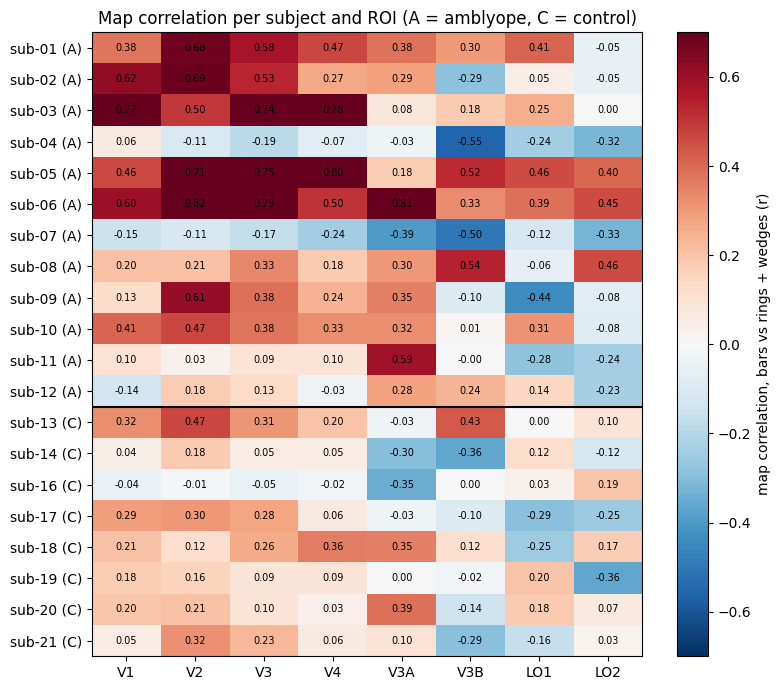

In [16]:
import matplotlib.pyplot as plt

df_b = df_sh.copy()
subj_order = [s for s in patients + controls if s in df_b.subject.unique()]

# Empirical noise spread per ROI: crossed-label correlations (no eye effect)
null_sd = df_b.groupby('roi').r_crossed.std().reindex(rois_to_keep)
df_b['below_noise'] = df_b.r_true < -2 * df_b.roi.map(null_sd)
print('SD of the crossed-label r per ROI (noise spread):')
print(null_sd.round(3).to_string())
print('\nSubject x ROI with r_true < -2 SD of the noise spread:')
print(df_b[df_b.below_noise][['subject', 'group', 'roi', 'r_true']].round(3).to_string(index=False))

# Heatmap subjects x ROIs
piv = df_b.pivot(index='subject', columns='roi', values='r_true').reindex(index=subj_order, columns=rois_to_keep)
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(piv.values, cmap='RdBu_r', vmin=-0.7, vmax=0.7, aspect='auto')
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.values[i, j]
        if np.isfinite(v):
            ax.text(j, i, '{:.2f}'.format(v), ha='center', va='center', fontsize=7)
ax.set_xticks(range(len(rois_to_keep)))
ax.set_xticklabels(rois_to_keep)
ax.set_yticks(range(len(subj_order)))
ax.set_yticklabels(['{} ({})'.format(s, 'A' if s in patients else 'C') for s in subj_order])
ax.axhline(sum(s in patients for s in subj_order) - 0.5, color='k', lw=1.5)
plt.colorbar(im, ax=ax, label='map correlation, bars vs rings + wedges (r)')
ax.set_title('Map correlation per subject and ROI (A = amblyope, C = control)')
plt.tight_layout()
fig.savefig('{}/od_v6_S4_r_heatmap.pdf'.format(fig_dir), bbox_inches='tight')
plt.show()

In [17]:
# Descriptors per subject and ROI: number of vertices, fit quality, difference between the pRFs of the two eyes
rows = []
for subject in subj_order:
    vd = vertex_data[subject]
    fe = vd['fe']
    ae = 'L' if fe == 'R' else 'R'
    d = {}
    for e, eye in eyes.items():
        deriv = load_surface_pycortex(L_fn=file_spec.format(pp_dir, subject, subject, task, eye, 'L', 'deriv'),
                                      R_fn=file_spec.format(pp_dir, subject, subject, task, eye, 'R', 'deriv'))['data_concat']
        d[e] = {name: deriv[i] for i, name in enumerate(maps_names_css)}
    rois = get_rois(subject=subject, surf_format='fsnative', rois_type='rois-mmp', mask=True, rois=None, hemis=None)
    dist = np.hypot(d[fe]['prf_x'] - d[ae]['prf_x'], d[fe]['prf_y'] - d[ae]['prf_y'])
    for roi in rois_to_keep:
        m = rois[roi] & vd['keep']
        rows.append({'subject': subject, 'roi': roi, 'n_vertices': m.sum(),
                     'rsq_min': np.nanmedian(np.minimum(d[fe]['prf_rsq'][m], d[ae]['prf_rsq'][m])),
                     'pos_shift_deg': np.nanmedian(dist[m]),
                     'pos_shift_rel': np.nanmedian(dist[m] / ((d[fe]['prf_size'][m] + d[ae]['prf_size'][m]) / 2)),
                     'ecc_diff_deg': np.nanmedian(d[ae]['prf_ecc'][m] - d[fe]['prf_ecc'][m]),
                     'size_ratio_ae_fe': np.nanmedian(d[ae]['prf_size'][m] / d[fe]['prf_size'][m]),
                     'ecc': np.nanmedian((d[fe]['prf_ecc'][m] + d[ae]['prf_ecc'][m]) / 2)})
    print('{}: done'.format(subject))
diag = pd.DataFrame(rows).merge(df_b[['subject', 'roi', 'group', 'r_true', 'r_crossed', 'below_noise']], on=['subject', 'roi'])

# Which descriptor goes with low / negative r? Spearman across subject x ROI (all, amblyopes, controls)
descs = ['n_vertices', 'rsq_min', 'pos_shift_deg', 'pos_shift_rel', 'ecc_diff_deg', 'size_ratio_ae_fe', 'ecc']
res = []
for desc in descs:
    row = {'descriptor': desc}
    for name, dd in [('all', diag), ('amblyopes', diag[diag.group == 'patient']), ('controls', diag[diag.group == 'control'])]:
        dd = dd.dropna(subset=[desc, 'r_true'])
        rho, p = stats.spearmanr(dd[desc], dd.r_true)
        row['rho_{}'.format(name)], row['p_{}'.format(name)] = rho, p
    res.append(row)
print(pd.DataFrame(res).set_index('descriptor').round(3).to_string())

# Same, removing the ROI effect (each descriptor and r centred per ROI): does it hold within ROIs?
dc = diag.copy()
for col in descs + ['r_true']:
    dc[col] = dc[col] - dc.groupby('roi')[col].transform('median')
print('\nWithin ROIs (values centred per ROI):')
print(pd.DataFrame([{'descriptor': desc, 'rho': stats.spearmanr(dc[desc], dc.r_true, nan_policy='omit')[0],
                     'p': stats.spearmanr(dc[desc], dc.r_true, nan_policy='omit')[1]} for desc in descs]).set_index('descriptor').round(3).to_string())

sub-01: done
sub-02: done
sub-03: done
sub-04: done
sub-05: done
sub-06: done
sub-07: done
sub-08: done
sub-09: done
sub-10: done
sub-11: done
sub-12: done
sub-13: done
sub-14: done
sub-16: done
sub-17: done
sub-18: done
sub-19: done
sub-20: done
sub-21: done
                  rho_all  p_all  rho_amblyopes  p_amblyopes  rho_controls  p_controls
descriptor                                                                            
n_vertices          0.457  0.000          0.498        0.000         0.464       0.000
rsq_min             0.423  0.000          0.518        0.000         0.416       0.001
pos_shift_deg      -0.211  0.007         -0.390        0.000        -0.165       0.193
pos_shift_rel      -0.164  0.038         -0.228        0.026        -0.215       0.088
ecc_diff_deg        0.087  0.272         -0.029        0.782         0.095       0.456
size_ratio_ae_fe    0.062  0.435          0.027        0.792        -0.015       0.909
ecc                 0.098  0.217          0.

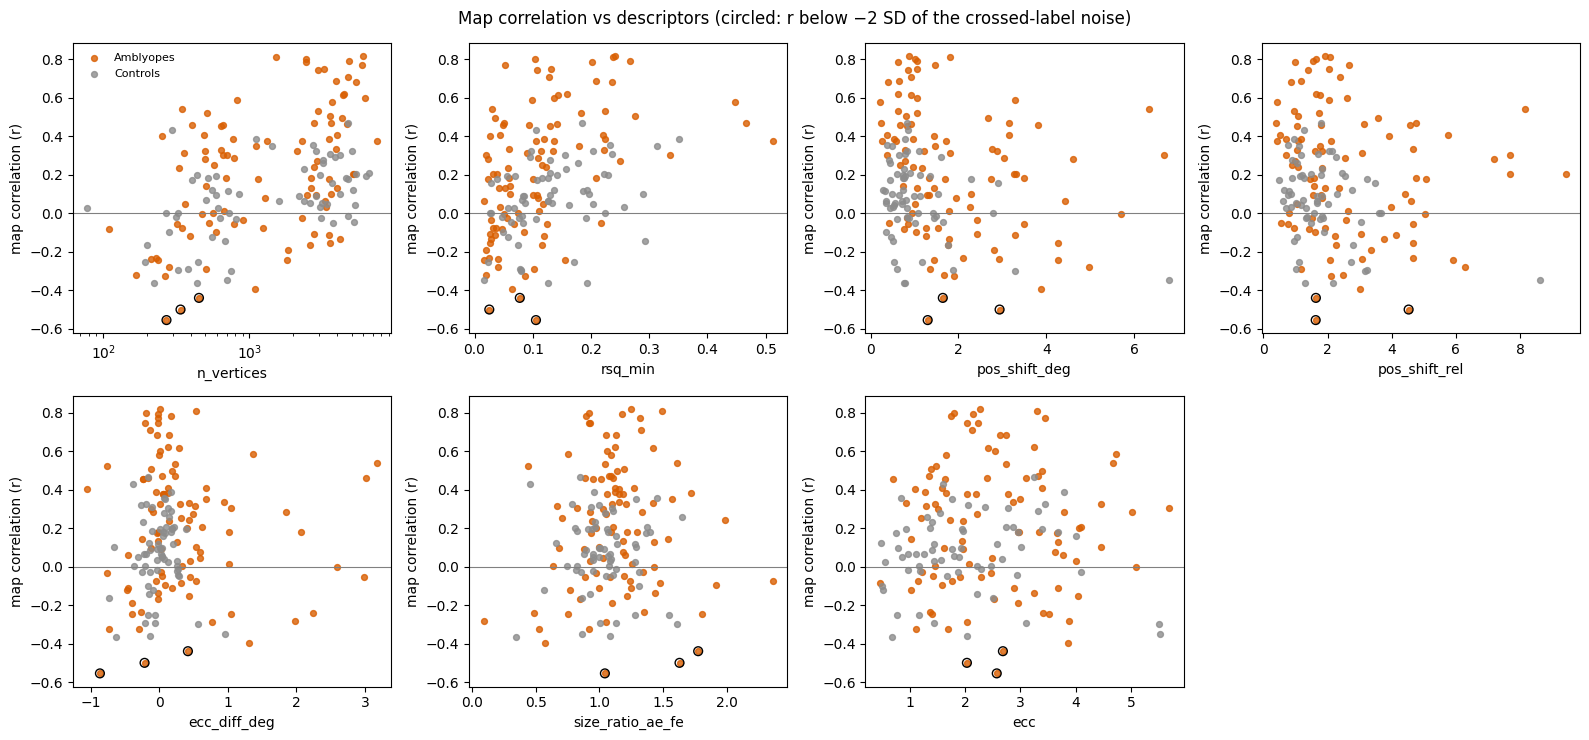

subject   group  r_true  pos_shift_rel  rsq_min
 sub-07 patient  -0.251          3.119    0.079
 sub-04 patient  -0.183          3.189    0.033
 sub-14 control  -0.041          1.517    0.113
 sub-16 control  -0.031          2.801    0.057
 sub-17 control   0.033          1.534    0.096
 sub-19 control   0.043          2.287    0.081
 sub-21 control   0.043          2.064    0.138
 sub-11 patient   0.048          3.521    0.068
 sub-12 patient   0.072          3.443    0.040
 sub-20 control   0.128          1.225    0.211
 sub-09 patient   0.139          1.545    0.101
 sub-18 control   0.167          1.318    0.189
 sub-13 control   0.226          1.531    0.174
 sub-02 patient   0.263          1.283    0.162
 sub-10 patient   0.269          2.900    0.087
 sub-08 patient   0.272          6.452    0.044
 sub-01 patient   0.393          0.614    0.322
 sub-03 patient   0.414          1.707    0.113
 sub-05 patient   0.535          2.264    0.113
 sub-06 patient   0.587          1.499  

In [18]:
# Scatter plots: r vs each descriptor (one dot per subject and ROI; amblyopes in colour, controls in grey)
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
for ax, desc in zip(axes.ravel(), descs):
    for group, color in [('patient', '#d95f02'), ('control', '0.55')]:
        dd = diag[diag.group == group]
        ax.scatter(dd[desc], dd.r_true, s=18, color=color, alpha=0.8, label=group_labels[group])
        neg = dd[dd.below_noise]
        ax.scatter(neg[desc], neg.r_true, s=40, facecolors='none', edgecolors='k')
    ax.axhline(0, color='grey', lw=0.8)
    ax.set_xlabel(desc)
    ax.set_ylabel('map correlation (r)')
    if desc in ['n_vertices']:
        ax.set_xscale('log')
axes.ravel()[-1].axis('off')
axes.ravel()[0].legend(frameon=False, fontsize=8)
plt.suptitle('Map correlation vs descriptors (circled: r below −2 SD of the crossed-label noise)')
plt.tight_layout()
fig.savefig('{}/od_v6_S4_r_vs_descriptors.pdf'.format(fig_dir), bbox_inches='tight')
plt.show()

# Per subject: mean r over the ROIs vs mean pRF shift between the eyes
per_subj = diag.groupby(['subject', 'group'])[['r_true', 'pos_shift_rel', 'rsq_min']].mean().reset_index()
print(per_subj.sort_values('r_true').round(3).to_string(index=False))
print('Amblyopes, subject mean r vs pRF shift: rho = {:.2f}, p = {:.3f}'.format(
    *stats.spearmanr(per_subj[per_subj.group == 'patient'].pos_shift_rel, per_subj[per_subj.group == 'patient'].r_true)))